In [2]:
import numpy as np 
import matplotlib.pyplot as plt
from hamiltonian_matrix import hamiltonian_matrix


In [8]:
# Infinite Potential Well
def infinite_well(L, interior_points, state_number):
    """ Solving particle in a box problem in 1-D
        L : width of the box
        interior_points : the number of grid points inside the wall
        state_number : quantum state to plot; starts from 0
    """
    
    if interior_points <= 0:
        raise ValueError("interior_points must be positive.")

    if state_number < 0 or state_number >= interior_points:
        raise ValueError("Invalid state_number.")
    
    
    dx = L/(interior_points+1)
    x_full = np.linspace(0, L, interior_points + 2)
    
    # Infinite well:  V = 0  inside the walls
    potential_values = np.zeros(interior_points)
    
    hamiltonian = hamiltonian_matrix(interior_points, dx, potential_values)
    
    energies, wavefunctions = np.linalg.eigh(hamiltonian)
    quantum_number = np.arange(1, len(energies)+1)
    analytical_energies = quantum_number**2 * np.pi**2 / (2 * L**2)
    
    # Adding the end points
    phi = np.concatenate(([0], wavefunctions[:, state_number], [0]))
    
    # Normalization of the wavefunction
    norm = np.sum(np.abs(phi)**2)*dx  
    phi_norm = phi / np.sqrt(norm)
    # Making the numerical wavefunction positive
    if phi_norm[np.argmax(np.abs(phi_norm))] < 0:
        phi_norm = -phi_norm
    analytical_phi = []
    for i in range(interior_points+2):
        a_phi = np.sqrt(2/L)*np.sin((state_number+1)*np.pi*x_full[i]/L)
        analytical_phi.append(a_phi)
    
    # Probability density of normalised wavefunction
    probability_density = np.abs(phi_norm)**2
    area = np.trapezoid(probability_density, dx=dx)
    return x_full, phi_norm, energies, probability_density, area, quantum_number, analytical_energies, analytical_phi

plotting wavefunctions for different states (n):

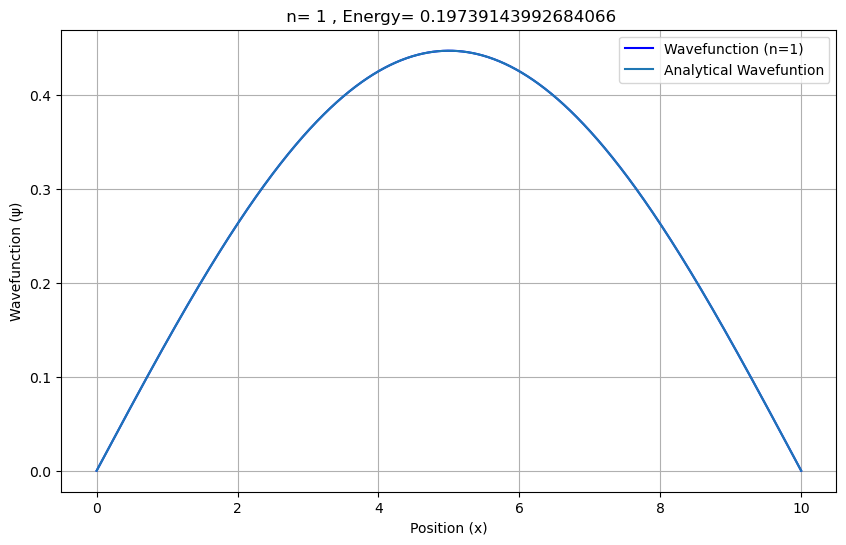

In [58]:
L = 10
interior_points = 1000
state_number = 0
x_full , phi_norm,energies, probability_density, area, quantum_number, analytical_energies, analytical_phi = infinite_well(L,interior_points, state_number)
    
plt.figure(figsize=(10,6))
plt.plot(x_full, phi_norm, label=f'Wavefunction (n={state_number+1}) ' , color='blue')
plt.plot(x_full, analytical_phi, label='Analytical Wavefuntion' )
plt.title(f' n= {state_number+1} , Energy= {energies[state_number+1]}')
plt.xlabel('Position (x)')
plt.ylabel('Wavefunction (ψ)')
plt.legend()
plt.grid(True)
plt.show()

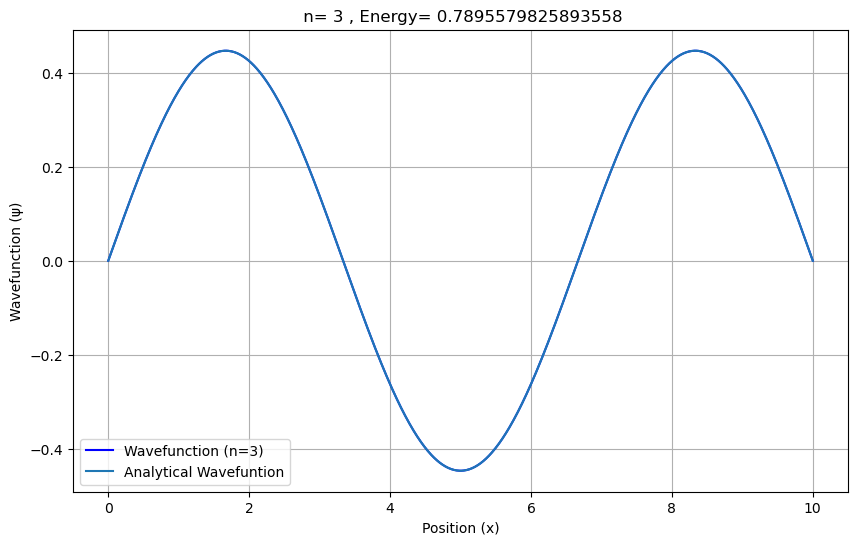

Probability Density

In [9]:
L = 10
interior_points = 1000
state_number = 0
x_full , phi_norm,energies, probability_density, area, quantum_number, analytical_energies, analytical_phi = infinite_well(L,interior_points, state_number)

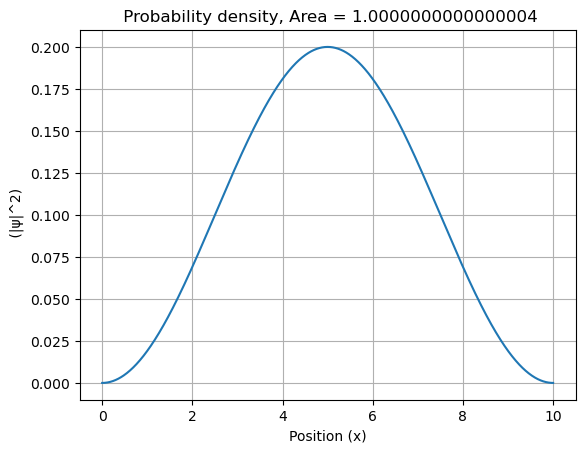

In [10]:

# plotting the probability density 
plt.plot(x_full, probability_density)
plt.title(f' Probability density, Area = {area}')
plt.xlabel('Position (x)')
plt.ylabel(' (|ψ|^2)')
plt.grid(True)
plt.show()

Plotting the Energy vs Quantum Number graph

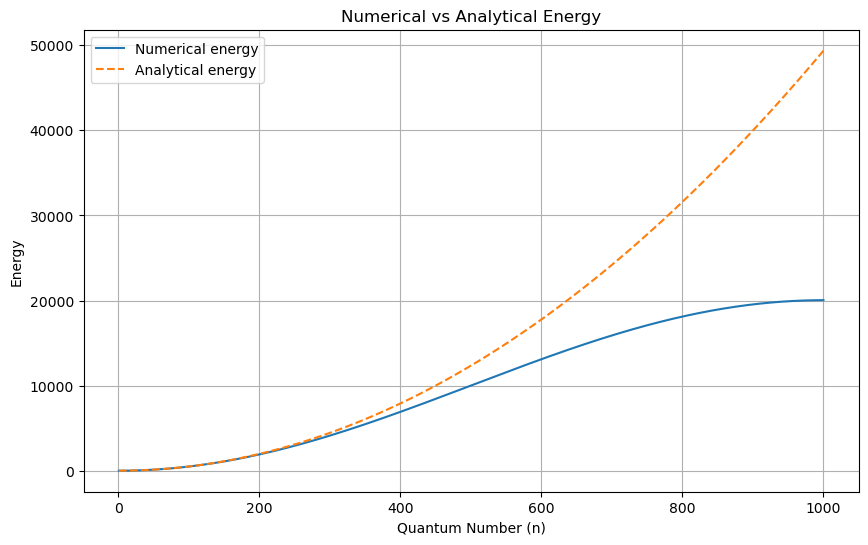

In [61]:
plt.figure(figsize=(10, 6))
plt.plot(quantum_number,energies,label="Numerical energy")
plt.plot(quantum_number,analytical_energies,label="Analytical energy", linestyle = '--' )
plt.xlabel("Quantum Number (n)")
plt.ylabel("Energy")
plt.title("Numerical vs Analytical Energy")
plt.legend()
plt.grid(True)
plt.show()

### SOLVING THIS PROBLEM USING SHOOTING METHOD

In [6]:
from rk4 import RK4

In [25]:
h_bar = 1973
m = 1
L = 10
n = 1
E = (n**2 * np.pi**2 * h_bar**2)/(2*m*L**2)

In [26]:
def function(S, x):
    psi, z = S
    d_psi = z
    d_z = -(2*m*E/h_bar**2)*psi
    return np.array([d_psi, d_z])

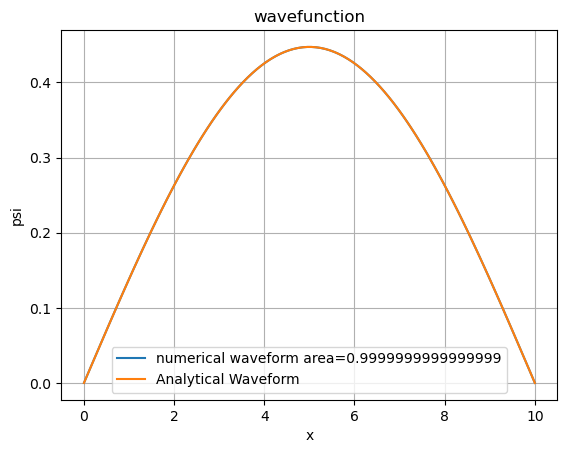

In [28]:
S0 = [0,1]
x = np.linspace(0,10.,100)
dx = x[1]-x[0]
sol = RK4(function, S0, x)
psi = sol[:,0]
sum = np.sum(np.abs(psi)**2)*dx
psi_norm = psi/np.sqrt(sum)
probability_density = np.abs(psi_norm)**2
area = np.trapezoid(probability_density,dx=dx)

plt.plot(x, psi_norm, label = f'numerical waveform area={area}')
plt.plot(x_full, analytical_phi, label='Analytical Waveform' )
plt.xlabel('x')
plt.ylabel("psi")
plt.title("wavefunction")
plt.legend()
plt.grid()
plt.show()

**Numerical parameters:**
- State number: 1
- Spatial domain: 0 to 10
- Numerical method: Shooting method

**Wavefunction:**

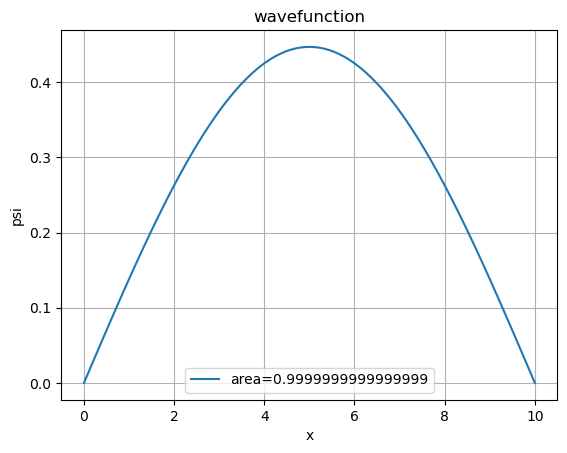



**Numerical parameters:**
- State number: 2
- Spatial domain: 0 to 20
- Numerical method: Shooting method

**Wavefunction:**

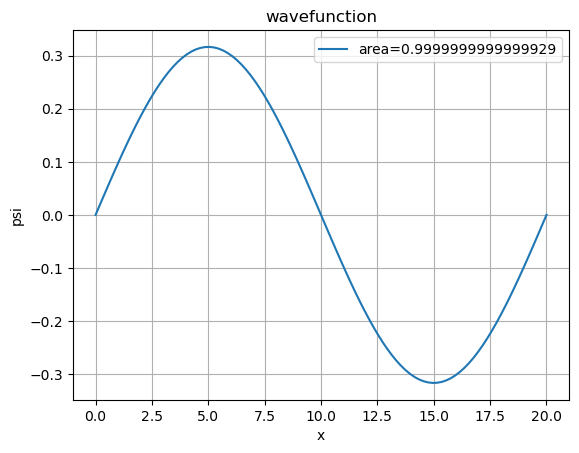


**Numerical parameters:**
- State number: 3
- Spatial domain: 0 to 30
- Numerical method: Shooting method

**Wavefunction:**

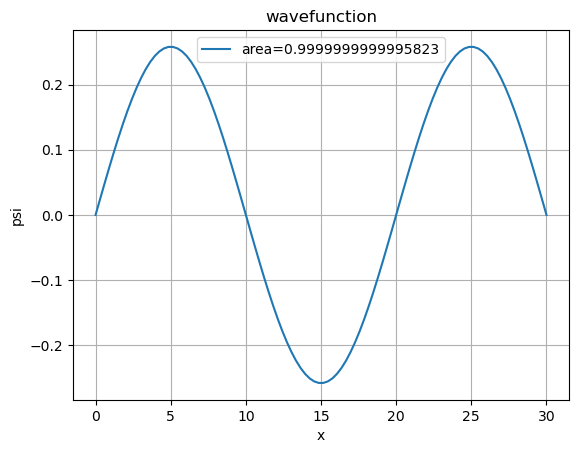
